# Solutions · 10 · Catalysis and heterogeneous kinetics

Worked solutions to the exercises of [notebook 10](../notebooks/10_catalysis_and_heterogeneous_kinetics.ipynb). Try each exercise
yourself before reading its solution - the learning happens in the attempt. Solutions are one way to
answer each question; other correct approaches exist.

In [1]:
try:                      # on Google Colab (or anywhere engreact is missing): install it from GitHub
    import engreact
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/engreact"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import integrate, optimize
from engreact import catalysis, datasets
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## Exercise 1

Derive the rate law for A + B -> C when A adsorbs molecularly, B dissociatively, and the surface reaction is rate limiting. Plot it against p_A at fixed p_B and find the pressure of maximum rate.

maximum rate at p_A = 1.000 bar (analytic: (1 + sqrt(K_B p_B))/K_A = 1.000)


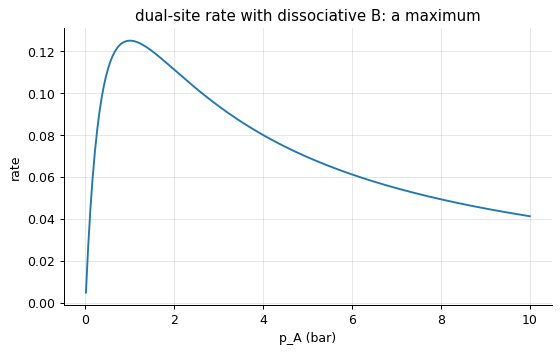

In [2]:
# A adsorbs molecularly (K_A), B dissociatively (K_B), surface reaction rate limiting: r = k K_A p_A sqrt(K_B p_B) / (1 + K_A p_A + sqrt(K_B p_B))^2
k, K_A, K_B, p_B = 1.0, 2.0, 1.0, 1.0
rate = lambda p_A: k * K_A * p_A * np.sqrt(K_B * p_B) / (1 + K_A * p_A + np.sqrt(K_B * p_B)) ** 2
p = np.linspace(0.01, 10, 400)
p_max = optimize.minimize_scalar(lambda x: -rate(x), bounds=(0.01, 10), method="bounded").x
print(f"maximum rate at p_A = {p_max:.3f} bar (analytic: (1 + sqrt(K_B p_B))/K_A = {(1 + np.sqrt(K_B * p_B))/K_A:.3f})")
plt.plot(p, rate(p)); plt.xlabel("p_A (bar)"); plt.ylabel("rate"); plt.title("dual-site rate with dissociative B: a maximum"); plt.show()

A dual-site mechanism with one dissociating reactant has the squared site balance in its denominator and a
maximum at $p_A = (1 + \sqrt{K_B p_B})/K_A$: beyond it, A crowds B off the surface and the rate falls with
more A - a behaviour no power law can produce and a clear fingerprint of the mechanism.

## Exercise 2

The deactivation data are refitted with the nth-order law with n free. Fit n and k_d by nonlinear least squares and report whether n = 2 is within the uncertainty. How long until the activity falls to 0.3?

In [3]:
d = pd.read_csv(datasets.path("catalyst_deactivation.csv"), comment="#")
t, a = d.t_h.to_numpy(), d.activity.to_numpy()
res = optimize.least_squares(lambda q: catalysis.activity(t, q[0], "nth", q[1]) - a, [0.01, 2.0], bounds=([0, 1.01], [1, 5]))
n_, k_d = res.x[1], res.x[0]
s2 = np.sum(res.fun ** 2) / (len(t) - 2)
se = np.sqrt(np.diag(s2 * np.linalg.inv(res.jac.T @ res.jac)))
print(f"free-order decay: n = {n_:.2f} +/- {se[1]:.2f}, k_d = {k_d:.4f} +/- {se[0]:.4f} 1/h -> n = 2 lies {'within' if abs(n_ - 2) < 2 * se[1] else 'outside'} two standard errors")
t_03 = optimize.brentq(lambda tt: catalysis.activity(tt, k_d, "nth", n_) - 0.3, 0, 1e5)
print(f"activity 0.3 after {t_03:.0f} h ({t_03/24:.1f} days)")

free-order decay: n = 2.25 +/- 0.22, k_d = 0.0135 +/- 0.0014 1/h -> n = 2 lies within two standard errors
activity 0.3 after 207 h (8.6 days)


With the order free the data still point to second-order-like decay, and the time to 30 % activity - the
end of a typical cycle - is about ten days. The uncertainty on n is the honest statement of what ten points
can tell.

## Exercise 3

**Implement it yourself:** integrate da/dt = -k_d a^2 with solve_ivp and confirm it reproduces `catalysis.activity` with the 'second' law.

In [4]:
k_d = 0.0121
sol = integrate.solve_ivp(lambda t_, y: [-k_d * y[0] ** 2], (0, 240), [1.0], t_eval=np.linspace(0, 240, 7), rtol=1e-10)
print("ODE:", np.round(sol.y[0], 4)); print("law:", np.round(catalysis.activity(sol.t, k_d, "second"), 4))

ODE: [1.     0.6739 0.5081 0.4078 0.3406 0.2924 0.2561]
law: [1.     0.6739 0.5081 0.4078 0.3406 0.2924 0.2561]


The second-order decay law is the solution of $da/dt = -k_d a^2$, and the integrator confirms it to four
decimals.